<a href="https://colab.research.google.com/github/ak12463-arch/gym-member-segments/blob/main/analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

SEED = 42

In [2]:
url = "https://raw.githubusercontent.com/ak12463-arch/gym-member-segments/main/gym_members.csv"
df = pd.read_csv(url)
print(df.shape)
df.head()

(330, 7)


,member_id,age,visits_per_month,avg_visit_minutes,classes_per_month,months_member,monthly_extras_spend
0,50001,45.0,7.0,45.0,7.0,17.0,38.0
1,50002,48.0,7.0,54.0,6.0,36.0,56.0
2,50003,63.0,11.0,41.0,6.0,47.0,36.0
3,50004,20.0,15.0,66.0,3.0,34.0,20.0
4,50005,31.0,16.0,59.0,0.0,39.0,22.0


In [3]:
train, test = train_test_split(df, test_size=0.3, random_state=SEED)

print("Training members:", train.shape)
print("Test members:", test.shape)

Training members: (231, 7)
Test members: (99, 7)


In [4]:
features = ["age", "visits_per_month", "avg_visit_minutes",
            "classes_per_month", "months_member", "monthly_extras_spend"]

X_train = train[features]
X_test = test[features]

In [5]:
scaler = StandardScaler()
scaler.fit(X_train)                    # learns mean and spread from TRAINING only

X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)   # uses the training numbers, no refit

print("Train means (should be ~0):", X_train_scaled.mean(axis=0).round(2))
print("Train stds  (should be ~1):", X_train_scaled.std(axis=0).round(2))
print("Test means  (close to 0, not exact):", X_test_scaled.mean(axis=0).round(2))

Train means (should be ~0): [-0.  0.  0. -0.  0. -0.]
Train stds  (should be ~1): [1. 1. 1. 1. 1. 1.]
Test means  (close to 0, not exact): [-0.12 -0.17 -0.03  0.06 -0.17 -0.03]


In [6]:
k_values = range(1, 9)
models = {}          # keep every fitted model, Step 3 needs them
train_spread = []

for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED)
    km.fit(X_train_scaled)
    models[k] = km
    train_spread.append(km.inertia_)
    print(f"k={k}: training spread = {km.inertia_:.1f}")

k=1: training spread = 1386.0
k=2: training spread = 950.3
k=3: training spread = 611.5
k=4: training spread = 336.0
k=5: training spread = 310.5
k=6: training spread = 287.2
k=7: training spread = 271.9
k=8: training spread = 254.6


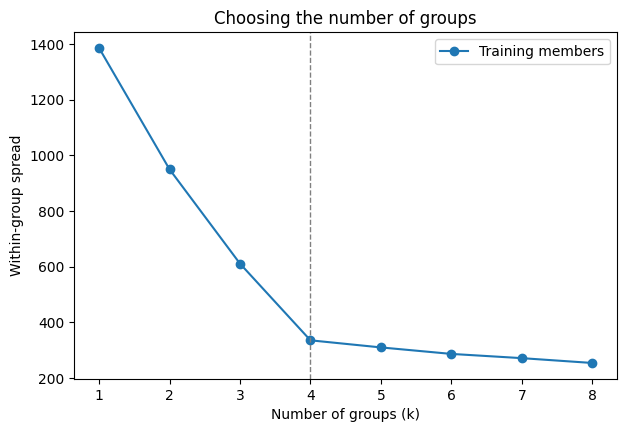

In [7]:
plt.figure(figsize=(7, 4.5))
plt.plot(list(k_values), train_spread, marker="o", label="Training members")
plt.axvline(4, color="gray", linestyle="--", linewidth=1)
plt.xlabel("Number of groups (k)")
plt.ylabel("Within-group spread")
plt.title("Choosing the number of groups")
plt.legend()
plt.show()

In [8]:
km4 = models[4]

centers = pd.DataFrame(
    scaler.inverse_transform(km4.cluster_centers_),   # back to years, visits, $ etc.
    columns=features
).round(1)
centers["members_in_training"] = np.bincount(km4.labels_)
centers

,age,visits_per_month,avg_visit_minutes,classes_per_month,months_member,monthly_extras_spend,members_in_training
0,27.3,3.0,40.7,0.9,5.8,9.0,46
1,64.2,12.0,46.5,3.9,57.8,17.4,45
2,33.2,16.0,64.5,0.9,30.3,24.9,79
3,42.6,9.4,55.1,7.0,24.0,47.3,61
